# ANÁLISIS Y PREDICCIÓN DE SERIES TEMPORALES

## Pedro Pablo Vicente González 48751969L

In [317]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import het_white
import warnings
from pmdarima import ARIMA
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error



### 1- Introducción, presentación de la serie y objetivo de estudio.

In [ ]:
df = pd.read_csv("/Minería y modelización 2/murciaTurismo.csv")

pd.set_option('display.max_columns', None)

df.head()
df.columns

# Todos los datos son definitivos y no hay notas, ajustamos la lectura de la columna "VALOR" 
# y elimino datos sobrantes

df['PERIODO'] = df['PERIODO'].astype(str)
df['VALOR'] = df['VALOR'].astype(str)

df['VALOR'] = df['PERIODO'] + '.' + df['VALOR']
df['IPC'] = df['VALOR']
df= df.drop(['PERIODO','TIPO DATO','NOTA','VALOR'], axis=1)
df['IPC'] = df['IPC'].astype(float) 

# Invierto el índice para que los datos aparezcan en orden temporal creciente,
# establezco el formato de fecha y cambio su nombre a 'Fecha'

df = df.iloc[::-1].reset_index(drop=False)
df['index'] = pd.to_datetime(df['index'], format='%YM%m')
df = df.set_index('index',drop=True)
df.index.name = 'Fecha'

df.head(-1)

,IPC
Fecha,
2002-01-01,64.595
2002-02-01,65.226
2002-03-01,66.420
2002-04-01,66.780
2002-05-01,66.977
...,...
2024-11-01,119.659
2024-12-01,121.576
2025-01-01,119.488


### 2- Representación gráfica y descomposición de la serie.

(array([10957., 12418., 13879., 15340., 16801., 18262., 19723., 21184.]),
 [Text(10957.0, 0, '2000'),
  Text(12418.0, 0, '2004'),
  Text(13879.0, 0, '2008'),
  Text(15340.0, 0, '2012'),
  Text(16801.0, 0, '2016'),
  Text(18262.0, 0, '2020'),
  Text(19723.0, 0, '2024'),
  Text(21184.0, 0, '2028')])

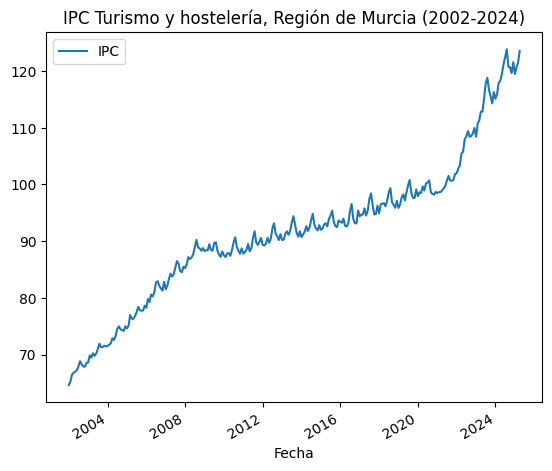

In [164]:
sns.lineplot(df)
plt.title('IPC Turismo y hostelería, Región de Murcia (2002-2024)')
plt.xticks(rotation=30,ha='right')

In [165]:
def plt_descomposicion_serie(serie,modelo):
    """
    Gráfico de descomposición estacional de la serie temporal, muestra y guarda la serie observada y sus componentes.

    Parámetros:
    - serie: datos input.
    - modelo: 'additive' o 'multiplicative'.
    """
    if modelo == 'additive':
        titulo= 'Descomposición estacional de la serie temporal, esquema aditivo'
    elif modelo == 'multiplicative':
        titulo= 'Descomposición estacional de la serie temporal, esquema multiplicativo'
    else:
        raise ValueError("Elige el tipo de modelo:'additive' o 'multiplicative'")
    result = seasonal_decompose(serie, model=modelo)
    plt.figure(figsize=(12, 8))
    plt.suptitle(titulo, y=0.91)
    plt.subplot(4, 1, 1)
    plt.plot(result.observed, label='Observado')
    plt.legend(loc='upper left')
    plt.subplot(4, 1, 2)
    plt.plot(result.trend, label='Tendencia')
    plt.legend(loc='upper left')
    plt.subplot(4, 1, 3)
    plt.plot(result.seasonal, label='Estacionalidad')
    plt.legend(loc='upper left')
    plt.subplot(4, 1, 4)
    plt.plot(result.resid, label='Residual')
    plt.legend(loc='upper left')
    
    plt.show()
    return result



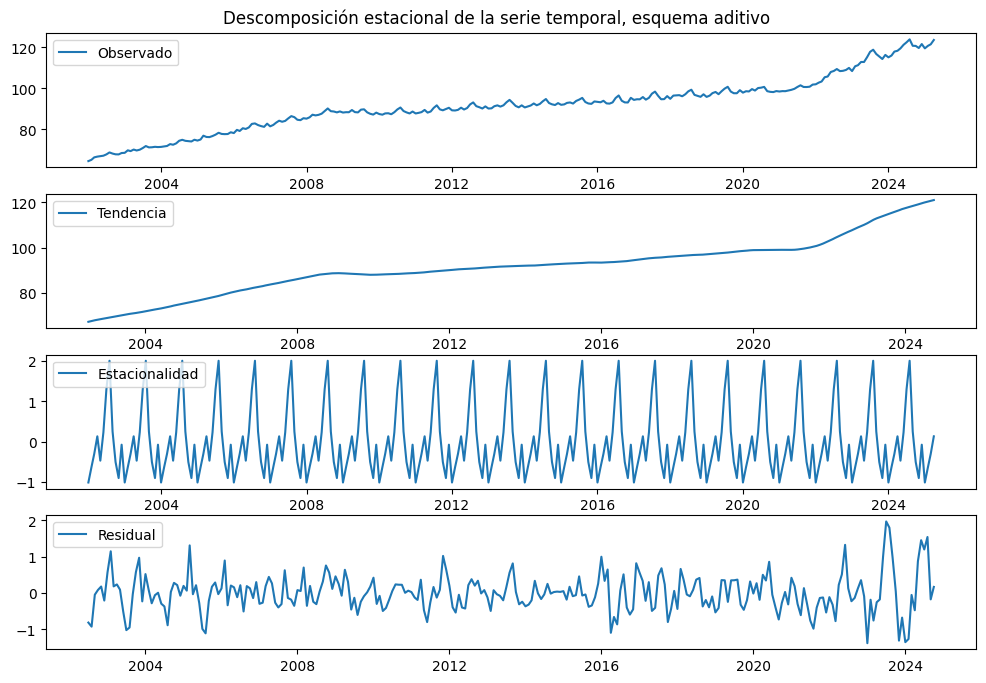

In [166]:
result_a = plt_descomposicion_serie(df['IPC'], 'additive')  # Modelo aditivo

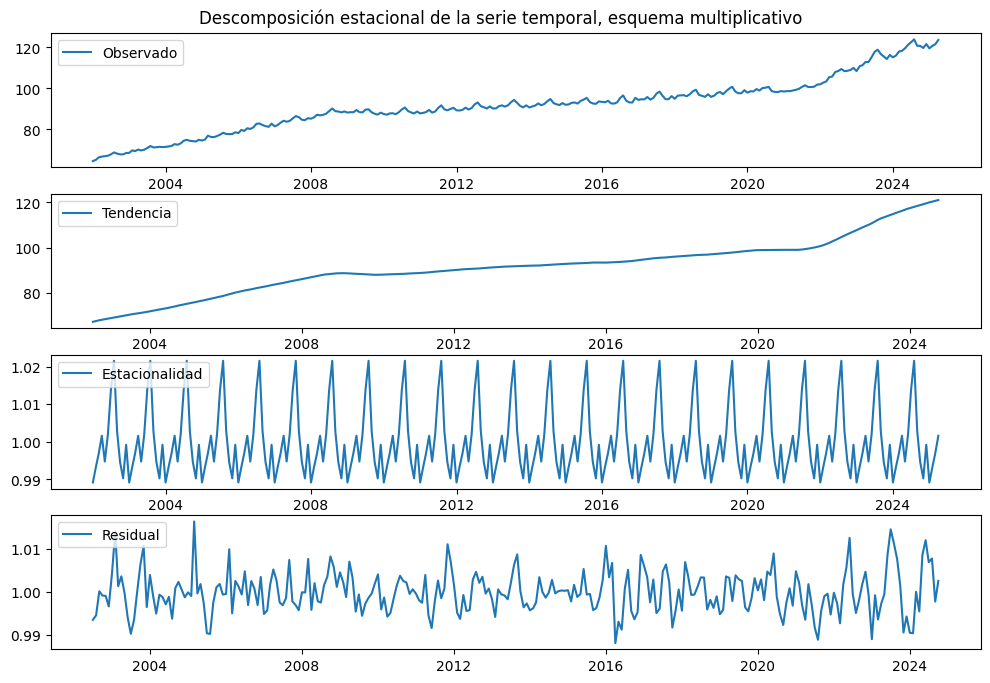

In [167]:
result_m = plt_descomposicion_serie(df['IPC'], 'multiplicative') # Modelo multiplicativo

La forma de calcular los coeficientes estacionales es distinta para esquema de modelo


In [168]:
result_a.seasonal  # Coeficientes estacionales para el esquema aditivo

Fecha
2002-01-01   -1.018569
2002-02-01   -0.636118
2002-03-01   -0.304790
2002-04-01    0.130680
2002-05-01   -0.474586
                ...   
2024-12-01   -0.077654
2025-01-01   -1.018569
2025-02-01   -0.636118
2025-03-01   -0.304790
2025-04-01    0.130680
Name: seasonal, Length: 280, dtype: float64

In [169]:
result_m.seasonal # Coeficientes estacionales para el esquema multiplicativo

Fecha
2002-01-01    0.989159
2002-02-01    0.993364
2002-03-01    0.996892
2002-04-01    1.001596
2002-05-01    0.994741
                ...   
2024-12-01    0.999200
2025-01-01    0.989159
2025-02-01    0.993364
2025-03-01    0.996892
2025-04-01    1.001596
Name: seasonal, Length: 280, dtype: float64

In [170]:
def plt_estac_tend(result, modelo):
    """
    Gráfico de descomposición estacional de la serie temporal, muestra la seria ajustada estacionalmente y su tendencia.

    Parámetros:
    - result: resultados de utilizar seasonal_decompose en una serie.
    - modelo: 'additive' o 'multiplicative'.
    """
    if modelo == 'additive':
        serie_desestacionalizada = result.observed - result.seasonal
        titulo= 'Descomposición estacional de la serie temporal, esquema aditivo'
    elif modelo == 'multiplicative':
        serie_desestacionalizada = result.observed / result.seasonal
        titulo= 'Descomposición estacional de la serie temporal, esquema multiplicativo'
    else:
        raise ValueError("Elige el tipo de modelo:'additive' o 'multiplicative'")

    plt.figure(figsize=(12, 8))
    plt.plot(result.observed, label='Observado', color='grey')
    plt.plot(serie_desestacionalizada, label='Serie ajustada estacionalmente', color='blue')
    plt.plot(result.trend, label='Tendencia', color='red')

    plt.legend()
    plt.title(titulo)
    plt.xlabel('Fecha')
    plt.ylabel('Cantidad')

    plt.show()


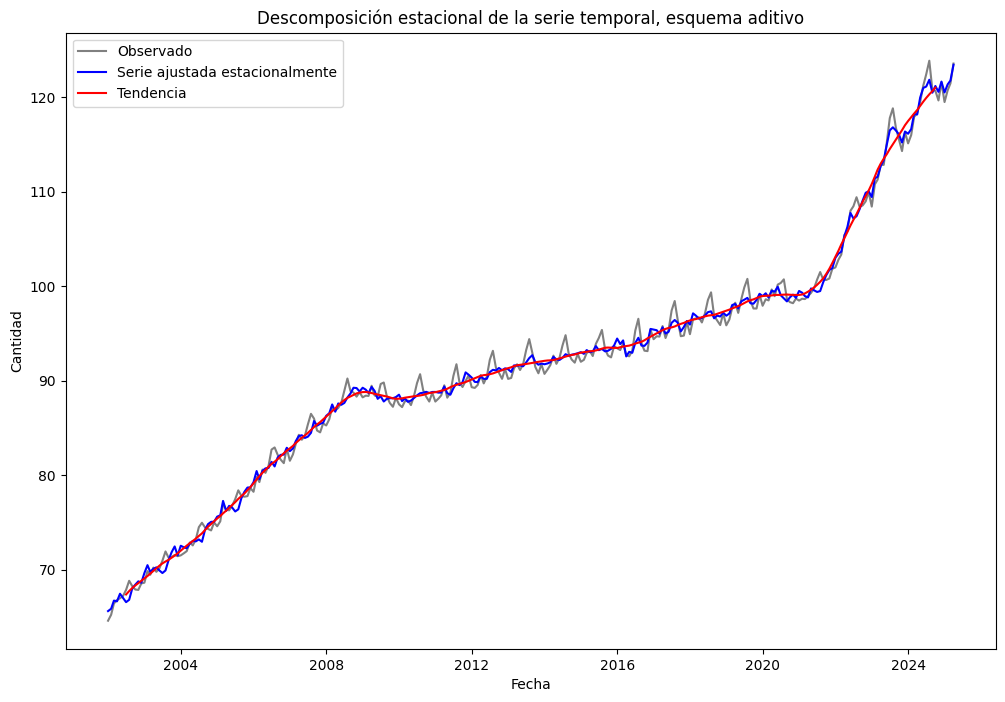

In [171]:
plt_estac_tend(result_a, 'additive')

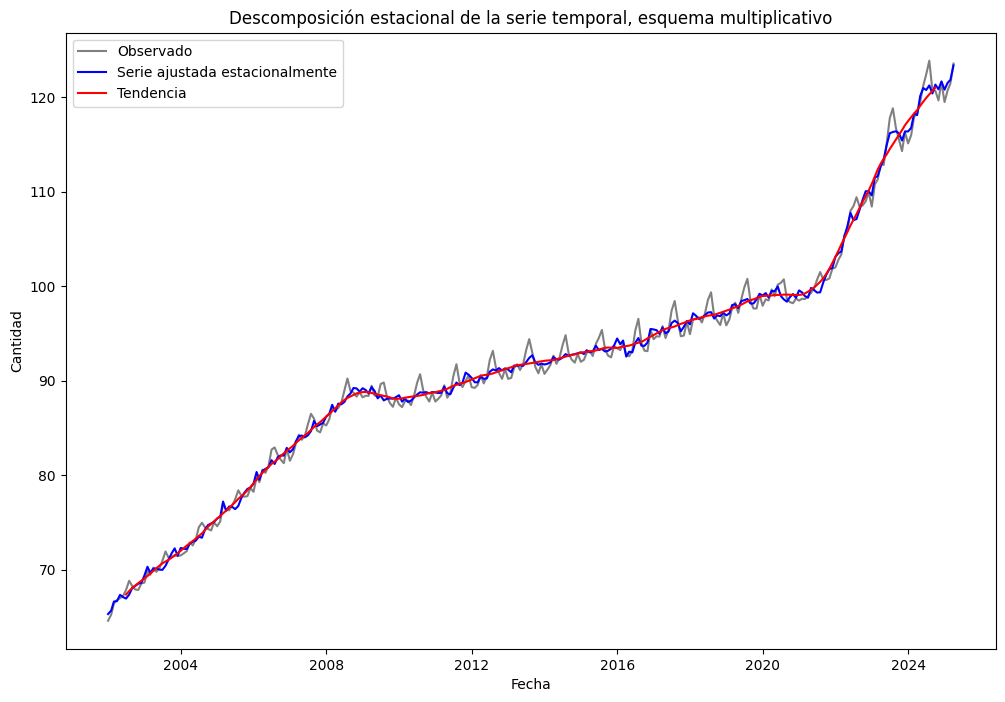

In [172]:
plt_estac_tend(result_m, 'multiplicative')

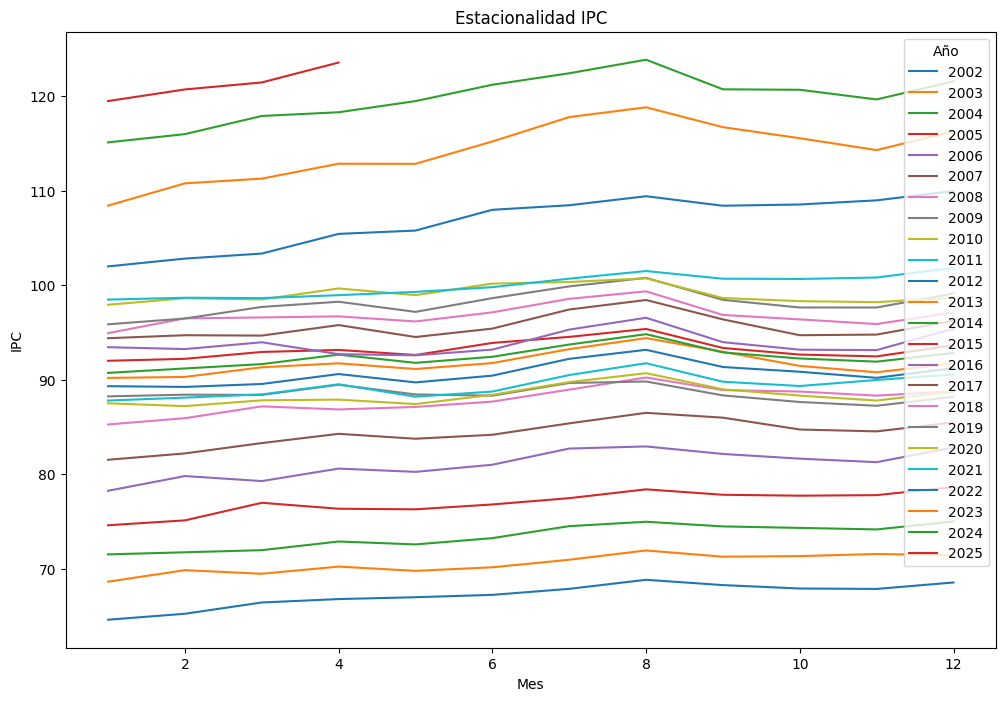

In [173]:

df['Año'] = pd.to_datetime(df.index, format='%YM%m').year

plt.figure(figsize=(12, 8))

for Año, grupo in df.groupby('Año'):
    plt.plot(grupo.index.month, grupo['IPC'], label=str(Año))

plt.legend(title='Año')
plt.title('Estacionalidad IPC')
plt.xlabel('Mes')
plt.ylabel('IPC')

plt.show()


### 3- Reserva de datos para comparar con las predicciones de cada método. 

In [174]:
dr = df.tail(12).index  # Úlltimo año de la serie (12 meses)

df_dr = df.drop(dr)  # Dataframe sin datos reservados

### 4- Modelo de suavizado exponencial más adecuado.

In [187]:
def Holt_Winters(serie,mostrar,gamma,tendencia, estacionalidad):  
    """con tendencia y estacionalidad: 'add' o 'multiplicative' """
    # Aplicar suavizado Holt-Winters. .fit(smoothing.seasonal = gamma).
    modelo_holt_winters = sm.tsa.ExponentialSmoothing(serie, trend=tendencia, seasonal=estacionalidad, seasonal_periods=12).fit(smoothing_seasonal = gamma)
    # Obtener predicciones para 1 año
    predicciones_hw = modelo_holt_winters.forecast(steps=12)

    # Crear un gráfico con matplotlib
    plt.figure(figsize=(10, 6))
    plt.plot(mostrar.index, mostrar, label='Observados', marker='x', linestyle='-', color='blue')
    plt.plot(mostrar.index, modelo_holt_winters.fittedvalues[mostrar.index], label='Suavizado Holt-Winters', linestyle='--', color='orange')
    plt.plot(predicciones_hw.index, predicciones_hw, label='Holt-Winters', linestyle='--',color='green')
    plt.xlabel('Fecha')
    plt.ylabel('IPC')
    plt.title(f'Suavizado y predicción Holt-Winters, Tendencia: {tendencia}, Estacionalidad: {estacionalidad}, Gamma: {gamma}')
    plt.legend()
    plt.xticks(rotation=30, ha='right')
    plt.show()

    return modelo_holt_winters.summary()


c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


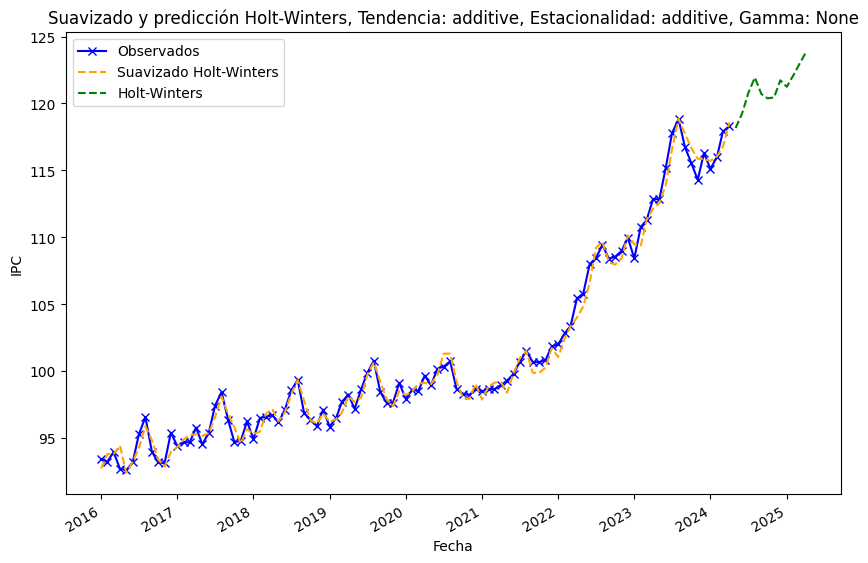

Dep. Variable:,IPC,No. Observations:,268
Model:,ExponentialSmoothing,SSE,78.661
Optimized:,True,AIC,-296.524
Trend:,Additive,BIC,-239.068
Seasonal:,Additive,AICC,-293.777
Seasonal Periods:,12,Date:,"Wed, 28 May 2025"
Box-Cox:,False,Time:,18:25:16
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.8153599,alpha,True
smoothing_trend,0.0567067,beta,True


In [190]:
Holt_Winters(df_dr['IPC'],df_dr.loc['2016':, 'IPC'], None , 'additive','additive')

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


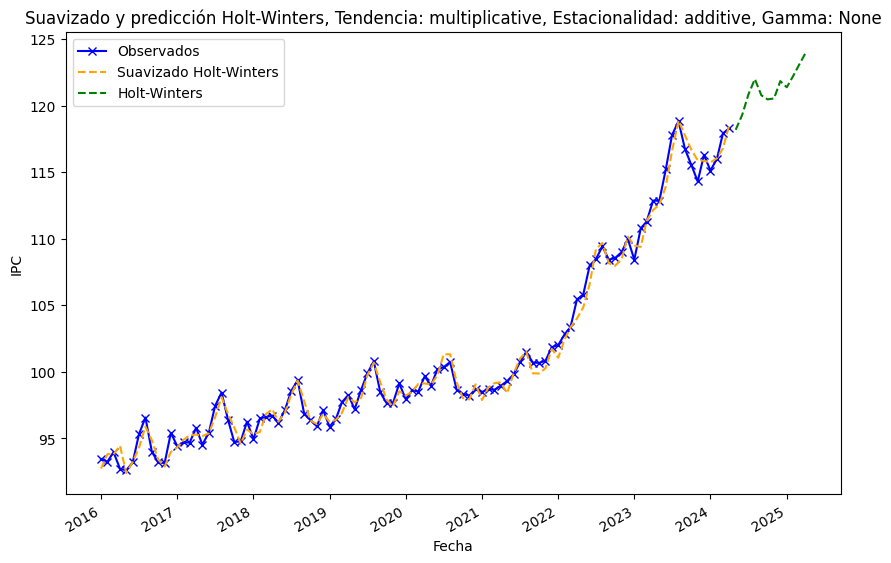

Dep. Variable:,IPC,No. Observations:,268
Model:,ExponentialSmoothing,SSE,78.721
Optimized:,True,AIC,-296.320
Trend:,Multiplicative,BIC,-238.864
Seasonal:,Additive,AICC,-293.573
Seasonal Periods:,12,Date:,"Wed, 28 May 2025"
Box-Cox:,False,Time:,18:19:38
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.8164669,alpha,True
smoothing_trend,0.0558713,beta,True


In [177]:
Holt_Winters(df_dr['IPC'],df_dr.loc['2016':, 'IPC'], None , 'multiplicative','additive')

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


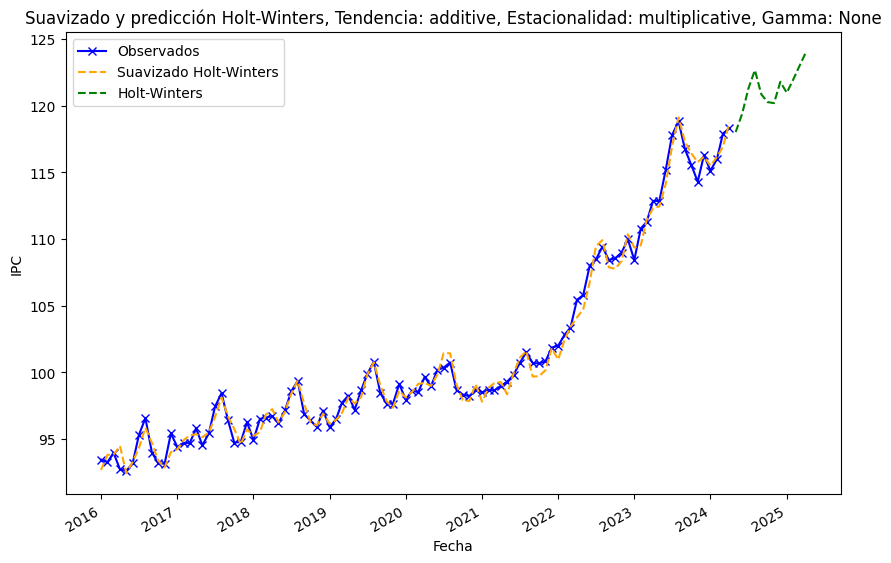

Dep. Variable:,IPC,No. Observations:,268
Model:,ExponentialSmoothing,SSE,69.937
Optimized:,True,AIC,-328.029
Trend:,Additive,BIC,-270.573
Seasonal:,Multiplicative,AICC,-325.282
Seasonal Periods:,12,Date:,"Wed, 28 May 2025"
Box-Cox:,False,Time:,18:19:38
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.7754692,alpha,True
smoothing_trend,0.0688237,beta,True


In [178]:
Holt_Winters(df_dr['IPC'],df_dr.loc['2016':, 'IPC'], None, 'additive','multiplicative')

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


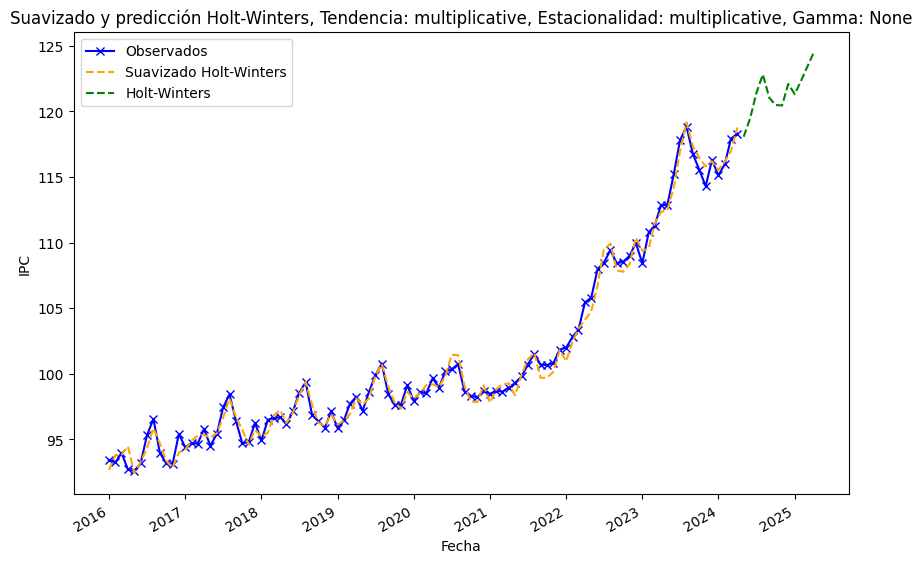

Dep. Variable:,IPC,No. Observations:,268
Model:,ExponentialSmoothing,SSE,70.176
Optimized:,True,AIC,-327.114
Trend:,Multiplicative,BIC,-269.658
Seasonal:,Multiplicative,AICC,-324.367
Seasonal Periods:,12,Date:,"Wed, 28 May 2025"
Box-Cox:,False,Time:,18:19:39
Box-Cox Coeff.:,None,,
,coeff,code,optimized
smoothing_level,0.7792457,alpha,True
smoothing_trend,0.0666891,beta,True


In [179]:
Holt_Winters(df_dr['IPC'],df_dr.loc['2016':, 'IPC'], None , 'multiplicative','multiplicative')

#### MODELO GANADOR: TENDENCIA MULTIPLICATIVA Y ESTACIONALIDAD ADITIVA

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


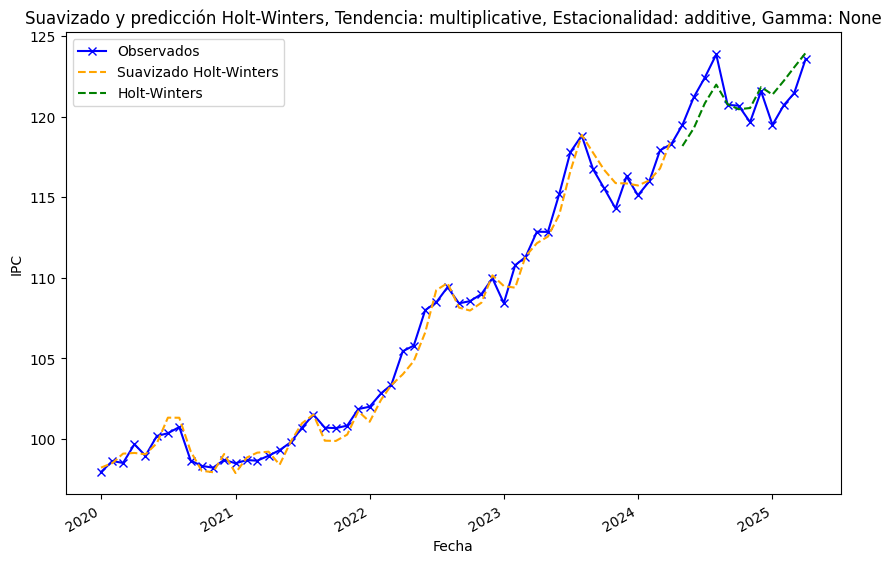

In [195]:
# Modelo ganador
modelo_holt_winters = sm.tsa.ExponentialSmoothing(df_dr['IPC'], trend='multiplicative', seasonal='additive', seasonal_periods=12).fit(smoothing_seasonal = None)
predicciones_hw = modelo_holt_winters.forecast(steps=12)

# Gráfico con los datos finales incluidos

plt.figure(figsize=(10, 6))
plt.plot(df.loc['2020':, 'IPC'].index, df.loc['2020':, 'IPC'], label='Observados', marker='x', linestyle='-', color='blue')
plt.plot(df_dr.loc['2020':, 'IPC'].index, modelo_holt_winters.fittedvalues[df_dr.loc['2020':, 'IPC'].index], label='Suavizado Holt-Winters', linestyle='--', color='orange')
plt.plot(predicciones_hw.index, predicciones_hw, label='Holt-Winters', linestyle='--',color='green')
plt.xlabel('Fecha')
plt.ylabel('IPC')
plt.title('Suavizado y predicción Holt-Winters, Tendencia: multiplicative, Estacionalidad: additive, Gamma: None')
plt.legend()
plt.xticks(rotation=30, ha='right')
plt.show()

### 5- Funciones de autocorrelación y autocorrelación parcial.

Text(0.5, 1.0, 'PACF')

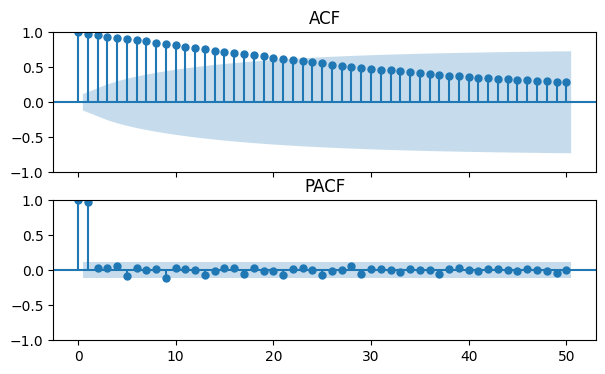

In [201]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(7, 4), sharex=True)
plot_acf(df['IPC'], ax=axs[0], lags=50, alpha=0.05)
axs[0].set_title('ACF')
plot_pacf(df['IPC'], ax=axs[1], lags=50, alpha=0.05)
axs[1].set_title('PACF')

Text(0.5, 1.0, 'IPC serie diferenciada (orden 1)')

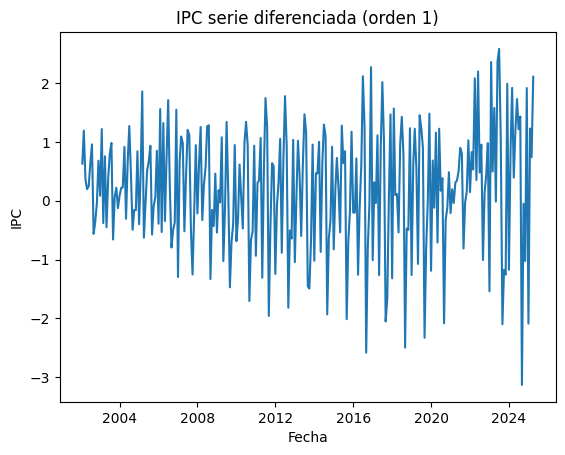

In [216]:
# Tenemos una serie no estacionaria, hacemos diferencias de primer orden

df_diff = df['IPC'].diff(1).dropna()
sns.lineplot(df_diff)
plt.title('IPC serie diferenciada (orden 1)')

Text(0.5, 1.0, 'PACF')

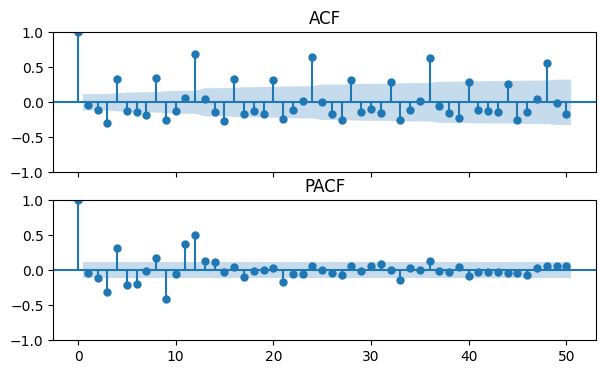

In [212]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(7, 4), sharex=True)
plot_acf(df_diff, ax=axs[0], lags=50, alpha=0.05)
axs[0].set_title('ACF')
plot_pacf(df_diff, ax=axs[1], lags=50, alpha=0.05)
axs[1].set_title('PACF')

In [218]:
resultado = adfuller(df_diff)

# Mostrar resultados
print("Estadístico ADF:", resultado[0])
print("Valor p:", resultado[1])
print("Retardos utilizados:", resultado[2])
print("Número de observaciones:", resultado[3])
print("Valores críticos:", resultado[4])
print("Información adicional:", resultado[5])

Estadístico ADF: -1.6539638070094707
Valor p: 0.4549740103517427
Retardos utilizados: 13
Número de observaciones: 265
Valores críticos: {'1%': -3.4552699038400827, '5%': -2.8725092359464526, '10%': -2.5726152830188678}
Información adicional: 492.48454325987973


In [217]:
# La serie sigue sin ser estacionaria, ha corregido la tendencia de la serie pero p= 0.454974 NoRH0 con H0: la serie es no estacionaria.
# Probamos a realizar desestacionalización mediante diferenciación de estacionalidad (12 meses).

df_seasonal_diff = df_diff.diff(12).dropna()

resultado2 = adfuller(df_seasonal_diff)

# Mostrar resultados
print("Estadístico ADF:", resultado2[0])
print("Valor p:", resultado2[1])
print("Retardos utilizados:", resultado2[2])
print("Número de observaciones:", resultado2[3])
print("Valores críticos:", resultado2[4])
print("Información adicional:", resultado2[5])

Estadístico ADF: -4.7535003885590035
Valor p: 6.669138214252253e-05
Retardos utilizados: 12
Número de observaciones: 254
Valores críticos: {'1%': -3.456360306409983, '5%': -2.8729872043802356, '10%': -2.572870232500465}
Información adicional: 479.41199547868416


Text(0.5, 1.0, 'IPC diferenciación estacional (orden 12)')

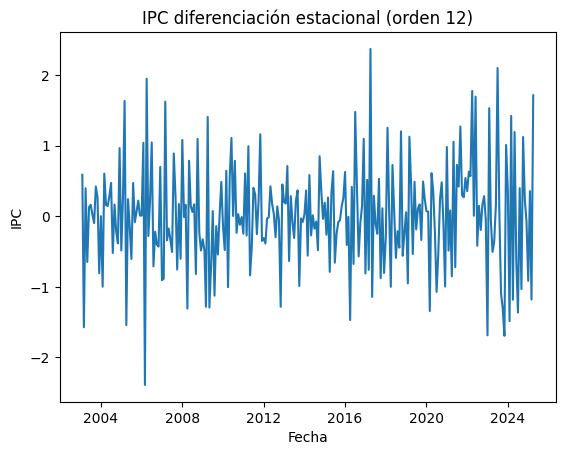

In [215]:
sns.lineplot(df_seasonal_diff)
plt.title('IPC diferenciación estacional (orden 12)')

Ya tenemos una serie estacionaria con la que trabajar.

Text(0.5, 1.0, 'PACF')

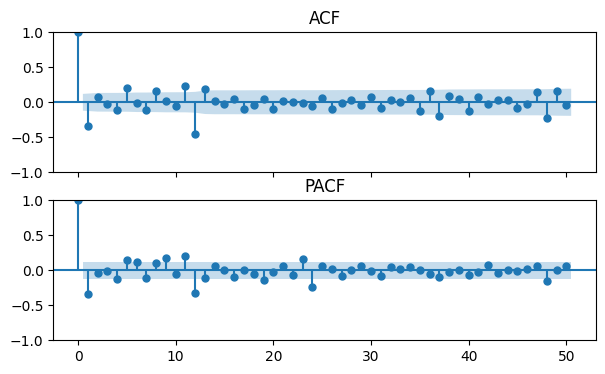

In [209]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(7, 4), sharex=True)
plot_acf(df_seasonal_diff, ax=axs[0], lags=50, alpha=0.05)
axs[0].set_title('ACF')
plot_pacf(df_seasonal_diff, ax=axs[1], lags=50, alpha=0.05)
axs[1].set_title('PACF')

## MODELO ARIMA

In [230]:
warnings.filterwarnings("ignore", category=UserWarning, message='Non-invertible|Non-stationary')
modelo = SARIMAX(endog = df['IPC'], order = (1, 1, 1), seasonal_order = (2, 1, 1, 12))
modelo_res = modelo.fit(disp=0)
warnings.filterwarnings("default")
modelo_res.summary()

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                IPC   No. Observations:                  280
Model:             SARIMAX(1, 1, 1)x(2, 1, 1, 12)   Log Likelihood                -240.373
Date:                            Thu, 29 May 2025   AIC                            492.746
Time:                                    14:00:25   BIC                            514.270
Sample:                                01-01-2002   HQIC                           501.392
                                     - 04-01-2025                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3851      0.302     -1.274      0.203      -0.978       0.207
ma.L1          0.1995      0.307      0.651      0.515      -0.401       0.800
ar.S.L12      -0.8878      0.177     -5.005      0.000      -1.235      -0.540
ar.S.L24      -0.4401      0.085     -5.171      0.000      -0.607      -0.273
ma.S.L12       0.3287      0.194      1.697      0.090      -0.051       0.708
sigma2         0.3470      0.025     14.088      0.000       0.299       0.395
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                13.96
Prob(Q):                              0.99   Prob(JB):                         0.00
Heteroskedasticity (H):               2.10   Skew:                             0.23
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.03
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [263]:
warnings.filterwarnings("ignore", category=UserWarning, message='Non-invertible|Non-stationary')
modelo = SARIMAX(endog = df['IPC'], order = (1, 1, 1), seasonal_order = (1, 1, 1, 12))
modelo_res = modelo.fit(disp=0)
warnings.filterwarnings("default")
modelo_res.summary()

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                IPC   No. Observations:                  280
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -236.665
Date:                            Thu, 29 May 2025   AIC                            483.329
Time:                                    15:49:05   BIC                            501.266
Sample:                                01-01-2002   HQIC                           490.534
                                     - 04-01-2025                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3844      0.283     -1.356      0.175      -0.940       0.171
ma.L1          0.1738      0.287      0.606      0.544      -0.388       0.736
ar.S.L12       0.0305      0.098      0.310      0.756      -0.162       0.223
ma.S.L12      -0.6932      0.085     -8.157      0.000      -0.860      -0.527
sigma2         0.3353      0.026     12.697      0.000       0.284       0.387
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 7.77
Prob(Q):                              0.98   Prob(JB):                         0.02
Heteroskedasticity (H):               1.83   Skew:                             0.24
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.68
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [267]:
warnings.filterwarnings("ignore", category=UserWarning, message='Non-invertible|Non-stationary')
modelo = SARIMAX(endog = df['IPC'], order = (3, 1, 2), seasonal_order = (3, 1, 1, 12))
modelo_res = modelo.fit(disp=0)
warnings.filterwarnings("default")
modelo_res.summary()

c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                  IPC   No. Observations:                  280
Model:             SARIMAX(3, 1, 2)x(3, 1, [1], 12)   Log Likelihood                -230.929
Date:                              Thu, 29 May 2025   AIC                            481.858
Time:                                      16:01:00   BIC                            517.731
Sample:                                  01-01-2002   HQIC                           496.268
                                       - 04-01-2025                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.1632      0.059    -19.679      0.000      -1.279      -1.047
ar.L2         -0.9849      0.082    -12.027      0.000      -1.145      -0.824
ar.L3         -0.1152      0.067     -1.726      0.084      -0.246       0.016
ma.L1          1.0061      0.023     44.043      0.000       0.961       1.051
ma.L2          0.9662      0.026     37.434      0.000       0.916       1.017
ar.S.L12      -1.0385      0.724     -1.434      0.152      -2.458       0.381
ar.S.L24      -0.5158      0.405     -1.275      0.202      -1.309       0.277
ar.S.L36      -0.0795      0.243     -0.327      0.744      -0.556       0.397
ma.S.L12       0.5383      0.717      0.750      0.453      -0.868       1.944
sigma2         0.3213      0.025     12.865      0.000       0.272       0.370
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                 7.77
Prob(Q):                              0.88   Prob(JB):                         0.02
Heteroskedasticity (H):               2.06   Skew:                             0.19
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.75
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
modelo = auto_arima(
    y=df['IPC'],
    start_p=0, start_q=0,
    max_p=4, max_q=4,
    start_P=0, start_Q=0,
    max_P=4, max_Q=4,
    m=12,
    seasonal=True,
    test='adf',
    d=None, D=None,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)
modelo.summary()

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=808.748, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=574.601, Time=0.14 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=687.875, Time=0.10 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=818.399, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=810.248, Time=0.03 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=0.29 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=513.963, Time=0.29 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=689.555, Time=0.08 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=515.878, Time=0.77 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=515.870, Time=0.57 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=648.134, Time=0.23 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=517.934, Time=1.04 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=523.164, Time=0.20 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept   : AIC=515.352, Time=0.32 sec
 ARIMA(1,1,1)(1,0,1)[12] intercept   

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                    y   No. Observations:                  280
Model:             SARIMAX(1, 1, 0)x(1, 0, [1], 12)   Log Likelihood                -251.982
Date:                              Thu, 29 May 2025   AIC                            513.963
Time:                                      15:00:38   BIC                            532.119
Sample:                                  01-01-2002   HQIC                           521.246
                                       - 04-01-2025                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0081      0.009      0.911      0.362      -0.009       0.026
ar.L1         -0.2082      0.054     -3.851      0.000      -0.314      -0.102
ar.S.L12       0.9784      0.013     75.868      0.000       0.953       1.004
ma.S.L12      -0.6653      0.055    -12.018      0.000      -0.774      -0.557
sigma2         0.3323      0.025     13.294      0.000       0.283       0.381
===================================================================================
Ljung-Box (L1) (Q):                   0.03   Jarque-Bera (JB):                 9.81
Prob(Q):                              0.87   Prob(JB):                         0.01
Heteroskedasticity (H):               1.93   Skew:                             0.25
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.77
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

### Validación de modelos

In [280]:
# dr = df.tail(12).index  : Úlltimo año de la serie (12 meses)
# df_dr = df.drop(dr)  : Dataframe sin datos reservados

warnings.filterwarnings("ignore", category=UserWarning, message='Non-invertible|Non-stationary')

# MODELO 3
modelo3 = SARIMAX(endog = df_dr['IPC'], order = (3, 1, 2), seasonal_order = (3, 1, 1, 12))
modelo_res3 = modelo3.fit(disp=0)
forecast3 = modelo_res3.forecast(steps=len(dr))
mae3 = mean_absolute_error(df.loc[dr, 'IPC'], forecast3)
mse3 = mean_squared_error(df.loc[dr, 'IPC'], forecast3)
rmse3 = np.sqrt(mse3)

print('ARIMA (3)')
print(f"MAE: {mae3:.2f}")
print(f"MSE: {mse3:.2f}")
print(f"RMSE: {rmse3:.2f}")
print("")

# MODELO 4- AUTOARIMA
modelo4 = SARIMAX(endog = df_dr['IPC'], order = (1, 1, 0), seasonal_order = (1, 0, 1, 12))
modelo_res4 = modelo4.fit(disp=0)
forecast4 = modelo_res4.forecast(steps=len(dr))

mae4 = mean_absolute_error(df.loc[dr, 'IPC'], forecast4)
mse4 = mean_squared_error(df.loc[dr, 'IPC'], forecast4)
rmse4 = np.sqrt(mse4)

print('AUTOARIMA (4)')
print(f"MAE: {mae4:.2f}")
print(f"MSE: {mse4:.2f}")
print(f"RMSE: {rmse4:.2f}")

warnings.filterwarnings("default")


c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


ARIMA (3)
MAE: 1.23
MSE: 1.95
RMSE: 1.40

AUTOARIMA (4)
MAE: 0.85
MSE: 1.06
RMSE: 1.03


c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


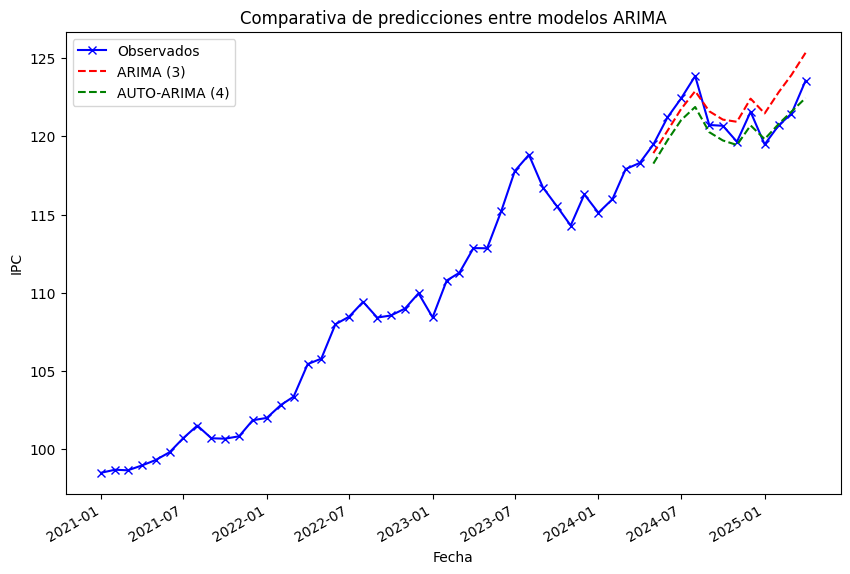

In [285]:
plt.figure(figsize=(10, 6))
plt.plot(df.loc['2021':, 'IPC'].index, df.loc['2021':, 'IPC'], label='Observados', marker='x', linestyle='-', color='blue')
plt.plot(forecast3.index, forecast3, label='ARIMA (3)', linestyle='--',color='red')
plt.plot(forecast4.index, forecast4, label='AUTO-ARIMA (4)', linestyle='--',color='green')
plt.xlabel('Fecha')
plt.ylabel('IPC')
plt.title('Comparativa de predicciones entre modelos ARIMA')
plt.legend()
plt.xticks(rotation=30, ha='right')
plt.show()

#### MODELO GANADOR: ARIMA (1, 1, 0) (1, 0, 1, 12)

### 7- Cálculo de predicciones e intervalos de confianza.

In [325]:
predicciones_statsmodels = modelo_res.get_forecast(steps=61).predicted_mean
predicciones_statsmodels.name = 'predicciones_statsmodels'

pred_hw = modelo_holt_winters.forecast(steps=36)
pred_arima = modelo_res4.get_forecast(steps=36).predicted_mean

# Intervalos de confianza calculados manualmente
    # Holt-Winter
residualshw = modelo_holt_winters.resid
std_residhw = residualshw.std()
lower_hw = pred_hw - 1.96 * std_residhw #IC al 95%
upper_hw = pred_hw + 1.96 * std_residhw
    # AutoARIMA
residualsaa = modelo_res4.resid
std_residaa = residualsaa.std()
lower_aa = pred_arima - 1.96 * std_residaa #IC al 95%
upper_aa = pred_arima + 1.96 * std_residaa



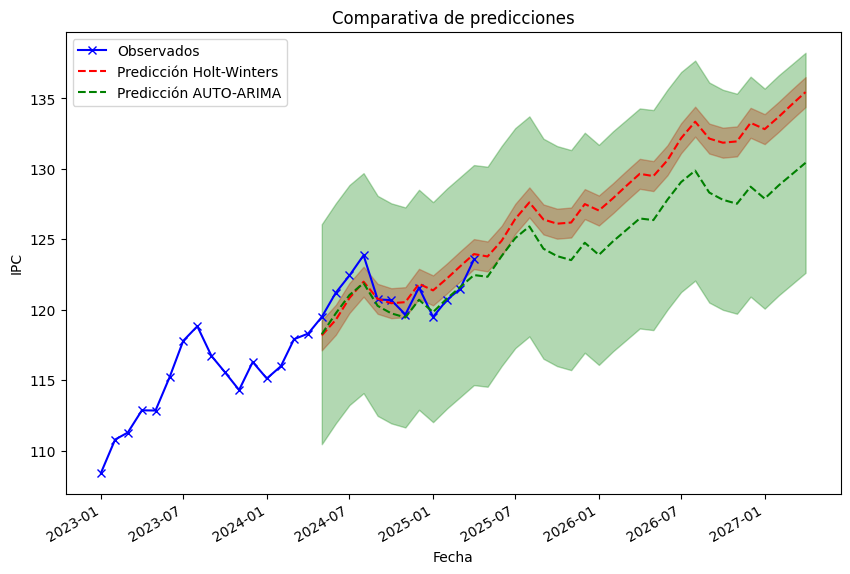

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(df.loc['2023':, 'IPC'].index, df.loc['2023':, 'IPC'], label='Observados', marker='x', linestyle='-', color='blue')

plt.plot(pred_hw.index, pred_hw, label='Predicción Holt-Winters', linestyle='--',color='red')
plt.fill_between(pred_hw.index, lower_hw, upper_hw, color='red', alpha=0.3)

plt.plot(pred_arima.index, pred_arima, label='Predicción AUTO-ARIMA', linestyle='--',color='green')
plt.fill_between(pred_arima.index, lower_aa, upper_aa, color='green', alpha=0.3)

plt.xlabel('Fecha')
plt.ylabel('IPC')
plt.title('Comparativa de predicciones')
plt.legend()
plt.xticks(rotation=30, ha='right')
plt.show()

In [323]:
# dr = df.tail(12).index  : Úlltimo año de la serie (12 meses)
# df_dr = df.drop(dr)  : Dataframe sin datos reservados

warnings.filterwarnings("ignore", category=UserWarning, message='Non-invertible|Non-stationary')

# HOLT-WINTERS
modelo_holt_winters = sm.tsa.ExponentialSmoothing(df_dr['IPC'], trend='multiplicative', seasonal='additive', seasonal_periods=12).fit(smoothing_seasonal = None)
pred_hw = modelo_holt_winters.forecast(steps=len(dr))
maehw = mean_absolute_error(df.loc[dr, 'IPC'], pred_hw)
msehw = mean_squared_error(df.loc[dr, 'IPC'], pred_hw)
rmsehw = np.sqrt(msehw)

print('HOLT-WINTERS')
print(f"MAE: {maehw:.2f}")
print(f"MSE: {msehw:.2f}")
print(f"RMSE: {rmsehw:.2f}")
print("")

# MODELO 4- AUTOARIMA
modelo4 = SARIMAX(endog = df_dr['IPC'], order = (1, 1, 0), seasonal_order = (1, 0, 1, 12))
modelo_res4 = modelo4.fit(disp=0)
forecast4 = modelo_res4.forecast(steps=len(dr))

mae4 = mean_absolute_error(df.loc[dr, 'IPC'], forecast4)
mse4 = mean_squared_error(df.loc[dr, 'IPC'], forecast4)
rmse4 = np.sqrt(mse4)

print('AUTOARIMA (4)')
print(f"MAE: {mae4:.2f}")
print(f"MSE: {mse4:.2f}")
print(f"RMSE: {rmse4:.2f}")

warnings.filterwarnings("default")


c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\ppabl\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


HOLT-WINTERS
MAE: 1.12
MSE: 1.74
RMSE: 1.32

AUTOARIMA (4)
MAE: 0.85
MSE: 1.06
RMSE: 1.03
